## D5 · Linear regression

Fit a line with linregress, check predictions and residuals, transform with logs and (optionally) use statsmodels.

In [1216]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

# Fish data (course data); we model the weight of Bream from their length
df_fish = pd.read_csv("data/fish.csv")
df_bream = df_fish[df_fish["species"] == "Bream"].copy()
col_x = df_bream["length1"]
col_y = df_bream["weight"]

### The fitted line

#### Fitting a line

**D5.01**

`slope, intercept, rvalue, pvalue, stderr = stats.linregress(x, y)`

The `stats.linregress(x, y)` function allows us to fit a straight line `y = slope × x + intercept` by least squares. It is useful for describing a linear relationship and predicting from it. Alternatively, `smf.ols` in statsmodels gives a fuller summary.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: a straight-line relationship, independent observations, residuals that are approximately normal, and residuals with equal variance (the LINE assumptions). The residual plots in the last section check them.

In [1217]:
# display the example data
df_bream[["length1", "weight"]].head()

,length1,weight
0,23.2,242.0
1,24.0,290.0
2,23.9,340.0
3,26.3,363.0
4,26.5,430.0


In [1218]:
slope, intercept, rvalue, pvalue, stderr = stats.linregress(col_x, col_y)
print(f"slope     = {slope:.2f} g per cm")

slope     = 54.55 g per cm


In [1219]:
print(f"intercept = {intercept:.2f} g")

intercept = -1035.35 g


In [1220]:
print(f"On average, each extra centimetre of length is associated with {slope:.1f} g more weight (R² = {rvalue ** 2:.2f}).")

On average, each extra centimetre of length is associated with 54.5 g more weight (R² = 0.88).


*See also:* Unpacking the output of `linregress` (A3) · R squared (D5) · Fitting a model with a formula (D5) · The LINE assumptions (D5)

#### R squared

**D5.02**

`rsquared = rvalue ** 2`

Squaring the correlation `rvalue` allows us to find R², the proportion of the variation in y explained by x. It is useful for judging how well the line fits (1 is perfect, 0 is none). Alternatively, `model.rsquared` in statsmodels.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Note: R² measures the strength of the straight-line fit only. A high R² does not show that the relationship is linear, and a low R² does not show that there is no relationship.

In [1221]:
slope, intercept, rvalue, pvalue, stderr = stats.linregress(col_x, col_y)
print(f"r         = {rvalue:.4f}")

r         = 0.9371


In [1222]:
rsquared = rvalue ** 2
print(f"R squared = {rsquared:.4f}")

R squared = 0.8781


In [1223]:
print(f"Length explains {rsquared:.1%} of the variation in weight; the other {1 - rsquared:.1%} is not explained by the line.")

Length explains 87.8% of the variation in weight; the other 12.2% is not explained by the line.


*See also:* Extracting single results from a model (D5) · Fitting a line (D5) · Checking the correlation first (D5) · The LINE assumptions (D5)

#### Reporting a regression

**D5.03**

`f"slope = {slope:.3g}"`

An f-string with format codes allows us to report the fitted equation and its quality neatly. It is useful for the write-up of any regression. Alternatively, a table of coefficients from statsmodels.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: the equation, R² and p-value are meaningful only if the LINE assumptions hold. Report them together with the residual checks.
A p-value below 0.001 is reported as "p < 0.001", otherwise to 2 significant figures:

In [1224]:
slope, intercept, rvalue, pvalue, stderr = stats.linregress(col_x, col_y)
p_text = "p < 0.001" if pvalue < 0.001 else f"p = {pvalue:.2g}"
print(f"weight = {slope:.3g} × length + {intercept:.3g}   (R² = {rvalue**2:.3f}, {p_text})")

weight = 54.5 × length + -1.04e+03   (R² = 0.878, p < 0.001)


*See also:* Fitting a line (D5) · Formatting numbers in an f-string (A1) · The LINE assumptions (D5) · Extracting single results from a model (D5) · Computing numbers instead of typing them (D6) · Reporting a p-value (D6)

#### Checking the correlation first

**D5.04**

`df['x'].corr(df['y']), stats.pearsonr(x, y)`

***(non-examinable)***

The `.corr()` method and `stats.pearsonr()` allow us to measure the strength of the linear relationship between two variables. It is useful as a first check before fitting a line. Alternatively, `df.corr()` gives every pair at once.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

In [1225]:
print(f"pandas : r = {col_x.corr(col_y):.4f}")

pandas : r = 0.9371


In [1226]:
res_r = stats.pearsonr(col_x, col_y)
print(f"scipy  : r = {res_r.statistic:.4f}, p = {res_r.pvalue:.3g}")

scipy  : r = 0.9371, p = 1.22e-16


*See also:* R squared (D5) · Drawing a correlation heatmap (C3) · Fitting a line (D5)

### Predictions and the fitted line

#### Adding a prediction column

**D5.05**

`df['pred'] = df['x'] * slope + intercept`

If we have fitted a line, then applying `x * slope + intercept` to the x column adds a column of predicted values. It is useful for comparing predictions with the real values. Alternatively, `model.predict()` in statsmodels.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

In [1227]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
df_bream[["length1", "weight"]].head(3)       # before: no predictions yet

,length1,weight
0,23.2,242.0
1,24.0,290.0
2,23.9,340.0


In [1228]:
df_bream["pred"] = df_bream["length1"] * slope + intercept
df_bream[["length1", "weight", "pred"]].head(3)      # after: a predicted weight for each fish

,length1,weight,pred
0,23.2,242.0,230.211993
1,24.0,290.0,273.851977
2,23.9,340.0,268.396979


*See also:* Fitting a line (D5) · Adding a calculated column (B4) · Residuals (D5)

#### Predicting a single value

**D5.06**

`x * slope + intercept`

Putting a chosen x into the fitted equation allows us to predict y for a new case. It is useful for answering "what weight would a 30 cm bream have?". Alternatively, `model.predict(pd.DataFrame({...}))` for several new values.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: the prediction assumes that the straight line still holds at the chosen length and that the residuals behave as in the data. It is a single best estimate; `linregress` gives no interval for it, but statsmodels does (see the linked example).

In [1229]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
print(f"range of lengths in the data: {col_x.min()} to {col_x.max()} cm")

range of lengths in the data: 23.2 to 38.0 cm


In [1230]:
new_length = 30
pred_weight = new_length * slope + intercept
print(f"predicted weight at {new_length} cm = {pred_weight:.0f} g")

predicted weight at 30 cm = 601 g


In [1231]:
f'A {new_length} cm bream is predicted to weigh about {pred_weight:.0f} g; {new_length} cm is ' + ('inside' if col_x.min() <= new_length <= col_x.max() else 'outside') + ' the range of lengths measured, so the prediction is ' + ('an interpolation.' if col_x.min() <= new_length <= col_x.max() else 'an extrapolation and may be unreliable.')

'A 30 cm bream is predicted to weigh about 601 g; 30 cm is inside the range of lengths measured, so the prediction is an interpolation.'

*See also:* Adding a prediction column (D5) · Extrapolation beyond the data (D5) · The LINE assumptions (D5)

#### Plotting a fitted line by hand

**D5.07**

`plt.plot([x0, x1], [y0, y1], 'r-')`

If we have the slope and intercept, then drawing a line between two fitted points on top of the scatter shows the data and the model together. It is useful when control over the line's style is needed. Alternatively, `sns.regplot` draws the points and line in one call.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

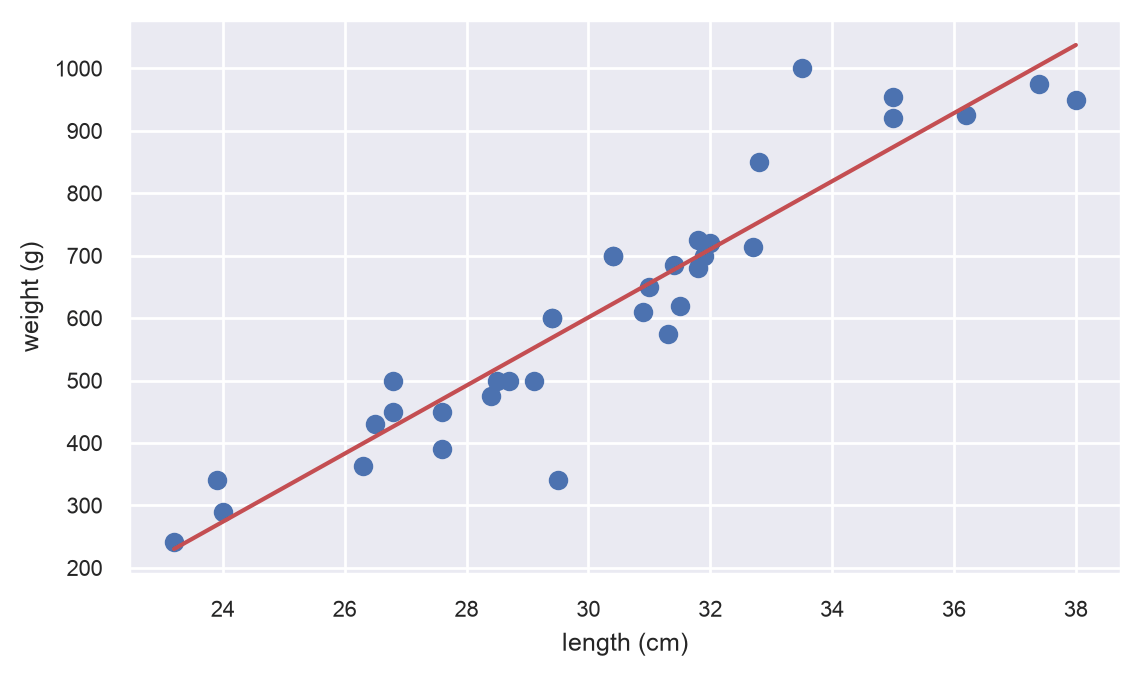

In [1232]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
x0, x1 = col_x.min(), col_x.max()
plt.scatter(col_x, col_y)
plt.plot([x0, x1], [x0 * slope + intercept, x1 * slope + intercept], "r-")
plt.xlabel("length (cm)")
plt.ylabel("weight (g)");

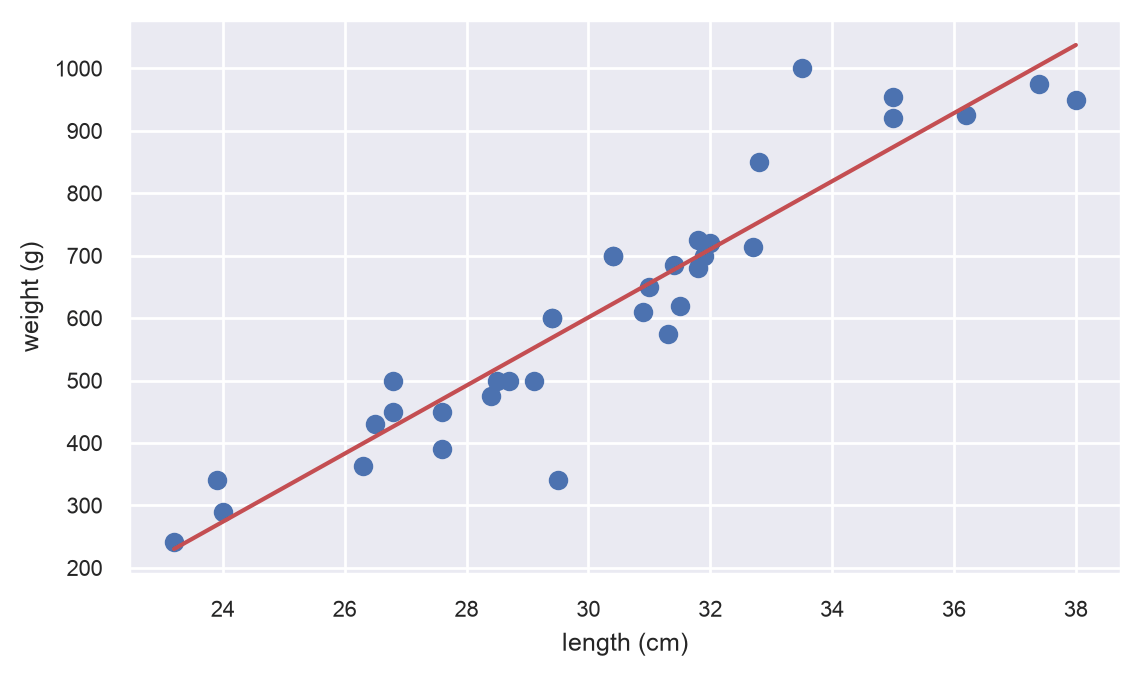

In [1233]:
# the same plot in object-oriented style (ax. methods)
slope, intercept, *_ = stats.linregress(col_x, col_y)
x0, x1 = col_x.min(), col_x.max()
fig, ax = plt.subplots()
ax.scatter(col_x, col_y)
ax.plot([x0, x1], [x0 * slope + intercept, x1 * slope + intercept], "r-")
ax.set_xlabel("length (cm)")
ax.set_ylabel("weight (g)");

*See also:* Drawing a scatter with a fitted line (C3) · Drawing a line between two points (C1) · Checking the fit with `regplot` (D5)

#### Writing the equation on the plot

**D5.08**

`plt.text(x, y, text)`

If we have a fitted line, then `plt.text` with an f-string puts the equation and R² on the plot. It is useful so the figure stands alone. Alternatively, put the equation in the title or caption.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

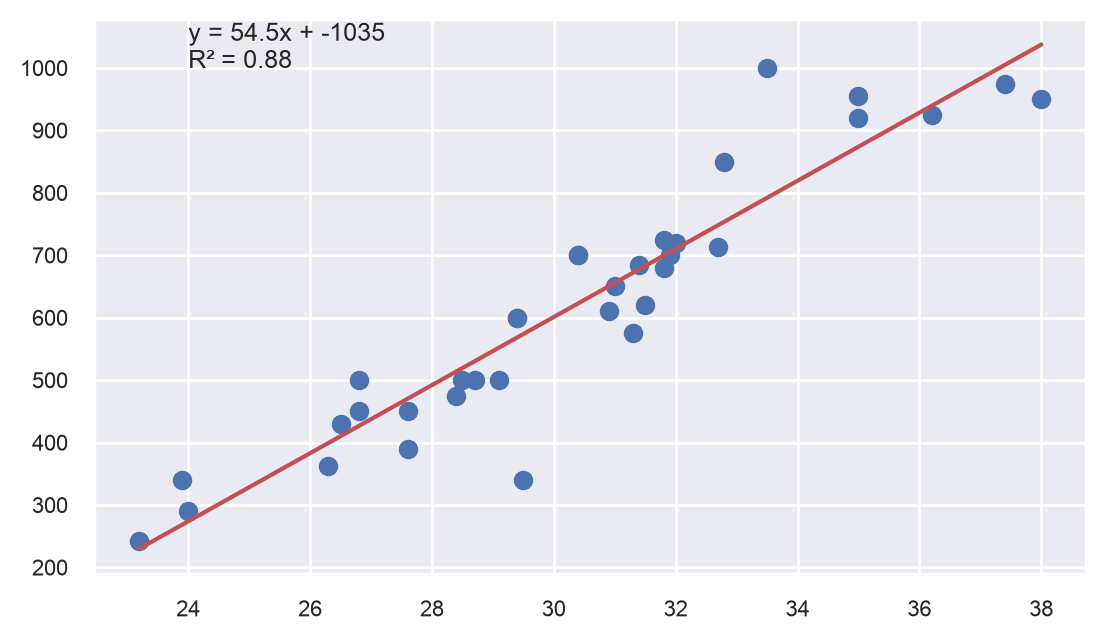

In [1234]:
slope, intercept, rvalue, *_ = stats.linregress(col_x, col_y)
plt.scatter(col_x, col_y)
plt.plot([col_x.min(), col_x.max()], [col_x.min() * slope + intercept, col_x.max() * slope + intercept], "r-")
plt.text(24, 1000, f"y = {slope:.1f}x + {intercept:.0f}\nR² = {rvalue**2:.2f}");

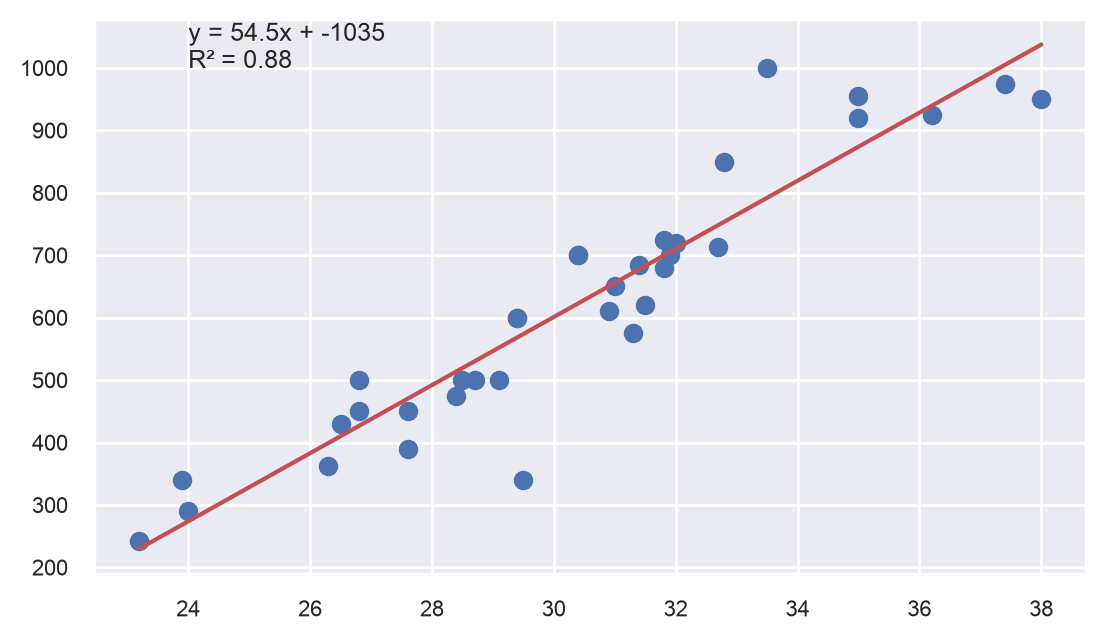

In [1235]:
# the same plot in object-oriented style (ax. methods)
slope, intercept, rvalue, *_ = stats.linregress(col_x, col_y)
fig, ax = plt.subplots()
ax.scatter(col_x, col_y)
ax.plot([col_x.min(), col_x.max()], [col_x.min() * slope + intercept, col_x.max() * slope + intercept], "r-")
ax.text(24, 1000, f"y = {slope:.1f}x + {intercept:.0f}\nR² = {rvalue**2:.2f}");

*See also:* Annotating with text (C1) · Plotting a fitted line by hand (D5) · Checking the fit with `regplot` (D5)

#### Checking the fit with `regplot`

**D5.09**

`sns.regplot(data=df, x='col_1', y='col_2', line_kws={'color': c})`

The `sns.regplot()` function allows us to draw a scatter plot, fitted line and confidence band in one call. It is useful as a quick check of the manual fit. Alternatively, `sns.lmplot` does the same and can split by group.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: the shaded band is a confidence interval for the line and relies on the LINE assumptions.

In [1236]:
# display the example data
df_bream[["length1", "weight"]].head()

,length1,weight
0,23.2,242.0
1,24.0,290.0
2,23.9,340.0
3,26.3,363.0
4,26.5,430.0


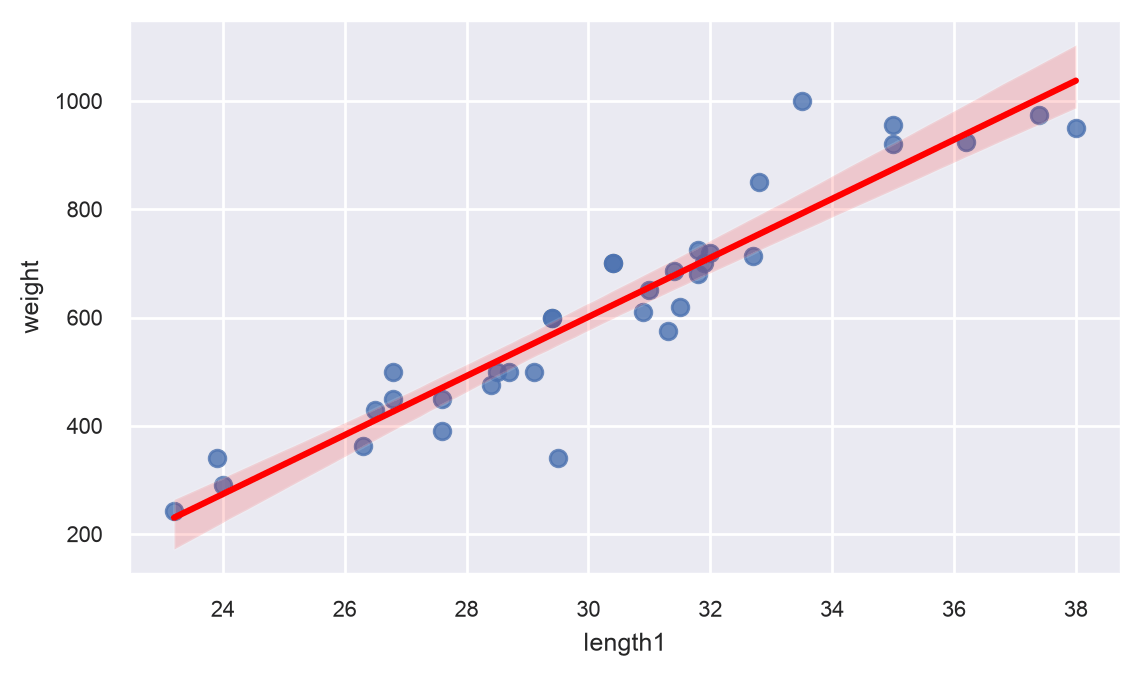

In [1237]:
sns.regplot(data=df_bream, x="length1", y="weight", line_kws={"color": "red"});

*See also:* A separate line per group (D5) · Drawing a scatter with a fitted line (C3) · Plotting a fitted line by hand (D5) · Predicted versus actual (D5) · The LINE assumptions (D5)

#### Predicted versus actual

**D5.10**

`plt.plot([lo, hi], [lo, hi], 'k--')`

If we have predictions and the real values, then plotting them against each other with a 1:1 line shows the quality of the fit. It is useful because points close to the dashed line mean accurate predictions. Alternatively, summarise with R² or the residual standard error.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

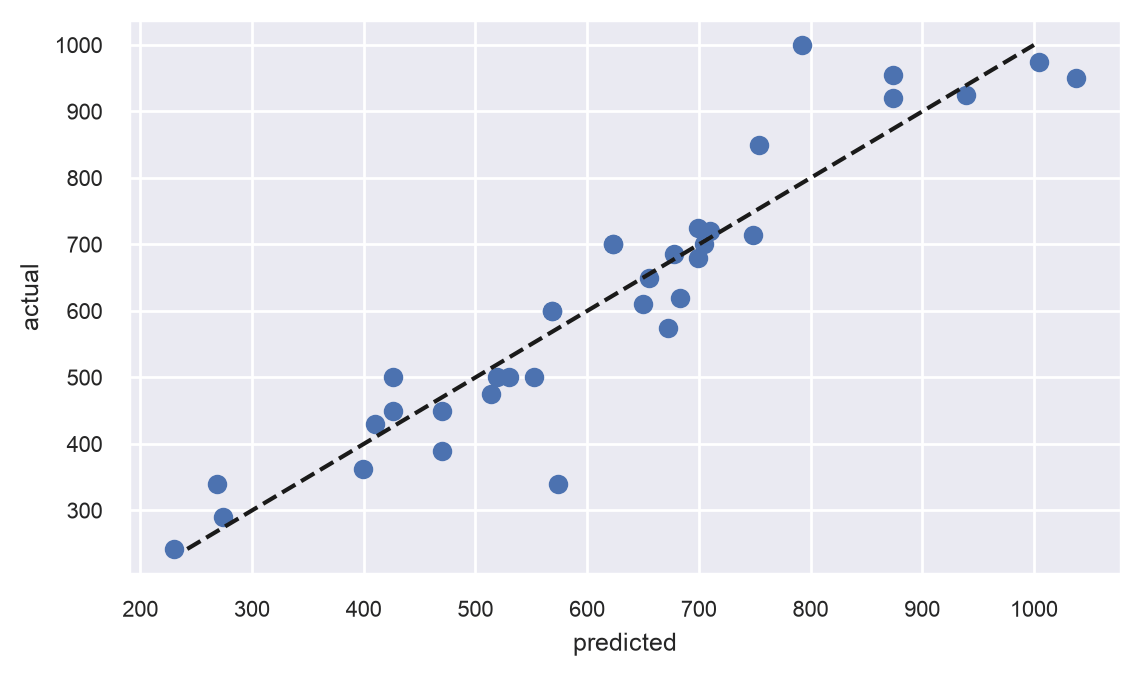

In [1238]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
col_pred = col_x * slope + intercept
lo, hi = col_y.min(), col_y.max()
plt.scatter(col_pred, col_y)
plt.plot([lo, hi], [lo, hi], "k--")
plt.xlabel("predicted")
plt.ylabel("actual");

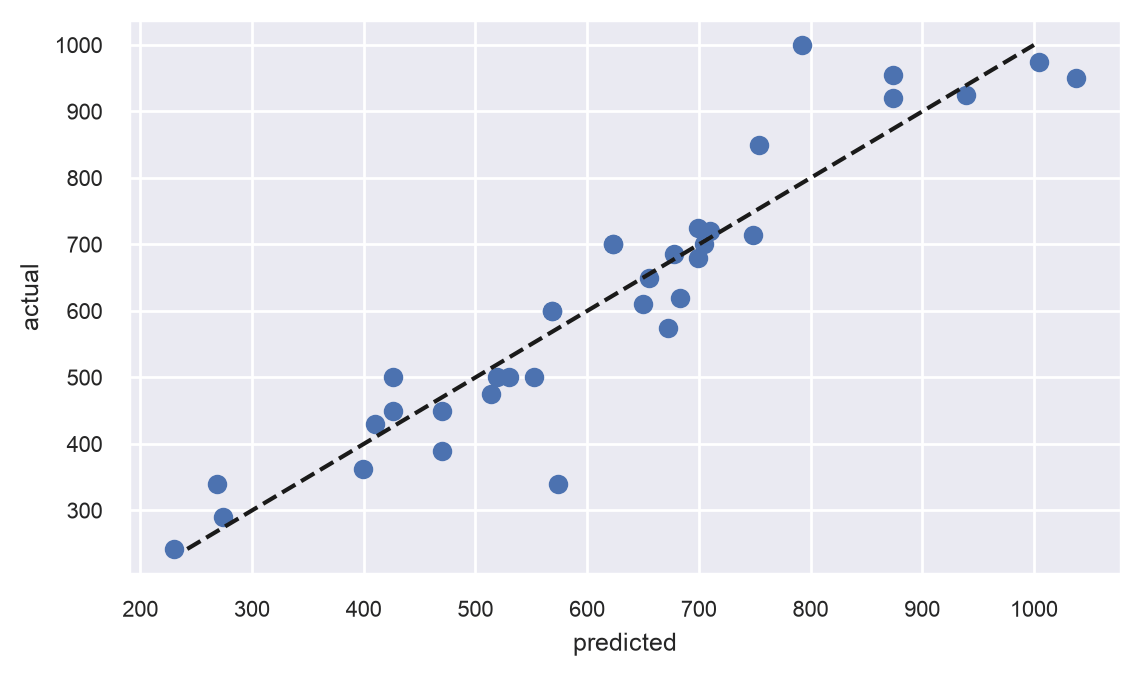

In [1239]:
# the same plot in object-oriented style (ax. methods)
slope, intercept, *_ = stats.linregress(col_x, col_y)
col_pred = col_x * slope + intercept
lo, hi = col_y.min(), col_y.max()
fig, ax = plt.subplots()
ax.scatter(col_pred, col_y)
ax.plot([lo, hi], [lo, hi], "k--")
ax.set_xlabel("predicted")
ax.set_ylabel("actual");

In [1240]:
mae = (col_y - col_pred).abs().mean()
print(f"On average the predicted weight differs from the actual weight by {mae:.0f} g ({mae / col_y.mean():.1%} of the mean weight), and {np.corrcoef(col_pred, col_y)[0, 1] ** 2:.1%} of the variation in weight is explained.")

On average the predicted weight differs from the actual weight by 52 g (8.4% of the mean weight), and 87.8% of the variation in weight is explained.


*See also:* Adding a prediction column (D5) · Residuals (D5) · Residuals versus fitted values (D5)

#### Extrapolation beyond the data

**D5.11**

`prediction at x = 0`

Predicting outside the range of the data allows us to see how a straight-line model can fail. It is useful as a warning: the relationship may not hold beyond what was measured. Alternatively, restrict predictions to the observed range.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

In [1241]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
print(f"lengths measured: {col_x.min()} to {col_x.max()} cm")

lengths measured: 23.2 to 38.0 cm


In [1242]:
pred_zero = 0 * slope + intercept
print(f"predicted weight of a fish of length 0: {pred_zero:.0f} g")

predicted weight of a fish of length 0: -1035 g


In [1243]:
f'The line predicts {pred_zero:.0f} g for a fish of length 0, ' + ('which is impossible (a weight cannot be negative), so the line must not be used outside the measured lengths.' if pred_zero < 0 else 'which should be checked against what is physically possible; the line should not be used outside the measured lengths.')

'The line predicts -1035 g for a fish of length 0, which is impossible (a weight cannot be negative), so the line must not be used outside the measured lengths.'

*See also:* Predicting a single value (D5) · Adding a prediction column (D5) · The LINE assumptions (D5)

### Residuals and assumptions

#### Residuals

**D5.12**

`df['res'] = df['y'] - df['pred']`

If we have actual and predicted values, then subtracting gives the residuals, the part the line does not explain. It is useful as the raw material for checking assumptions. Alternatively, `model.resid` in statsmodels.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

In [1244]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
df_bream["pred"] = df_bream["length1"] * slope + intercept
df_bream[["weight", "pred"]].head(3)

,weight,pred
0,242.0,230.211993
1,290.0,273.851977
2,340.0,268.396979


In [1245]:
df_bream["res"] = df_bream["weight"] - df_bream["pred"]
df_bream[["weight", "pred", "res"]].head(3)

,weight,pred,res
0,242.0,230.211993,11.788007
1,290.0,273.851977,16.148023
2,340.0,268.396979,71.603021


*See also:* Fitted values and residuals (D5) · Adding a prediction column (D5) · Residuals versus fitted values (D5)

#### Residuals versus fitted values

**D5.13**

`plt.scatter(fitted, residuals); plt.axhline(0, ...)`

If we have residuals and fitted values, then plotting one against the other checks the linear and equal-variance assumptions. It is useful because curves or a funnel shape show problems, whereas a random cloud around 0 is good. Alternatively, `sns.residplot` does it directly from the data.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

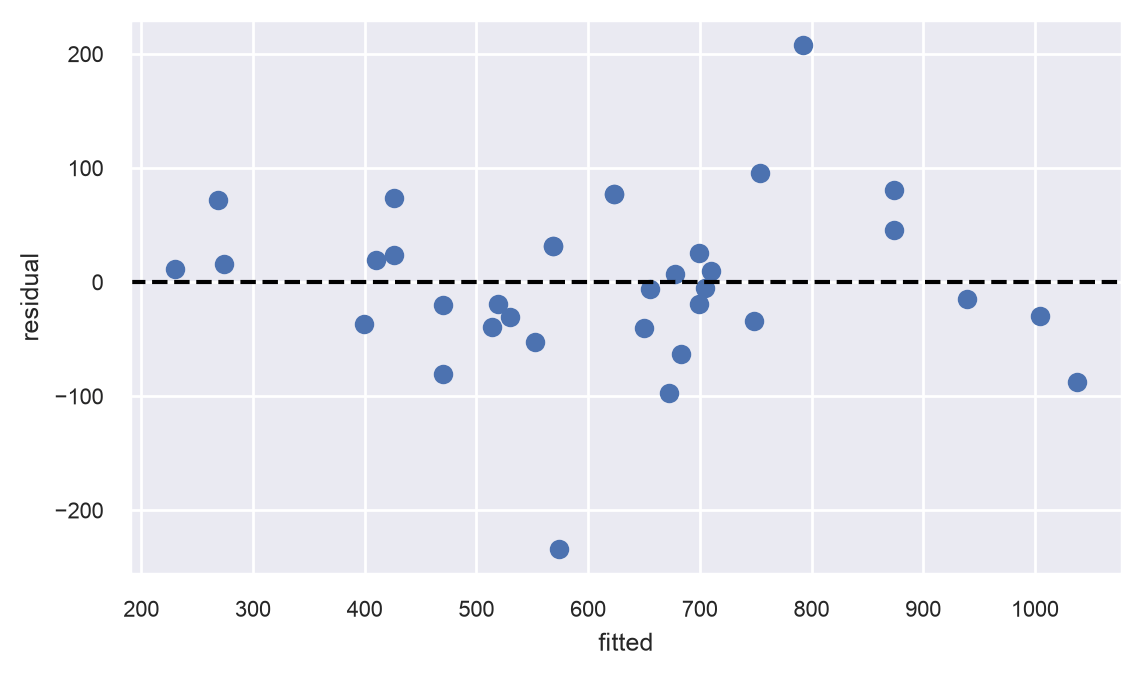

In [1246]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
col_pred = col_x * slope + intercept
col_res = col_y - col_pred
plt.scatter(col_pred, col_res)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("fitted")
plt.ylabel("residual");

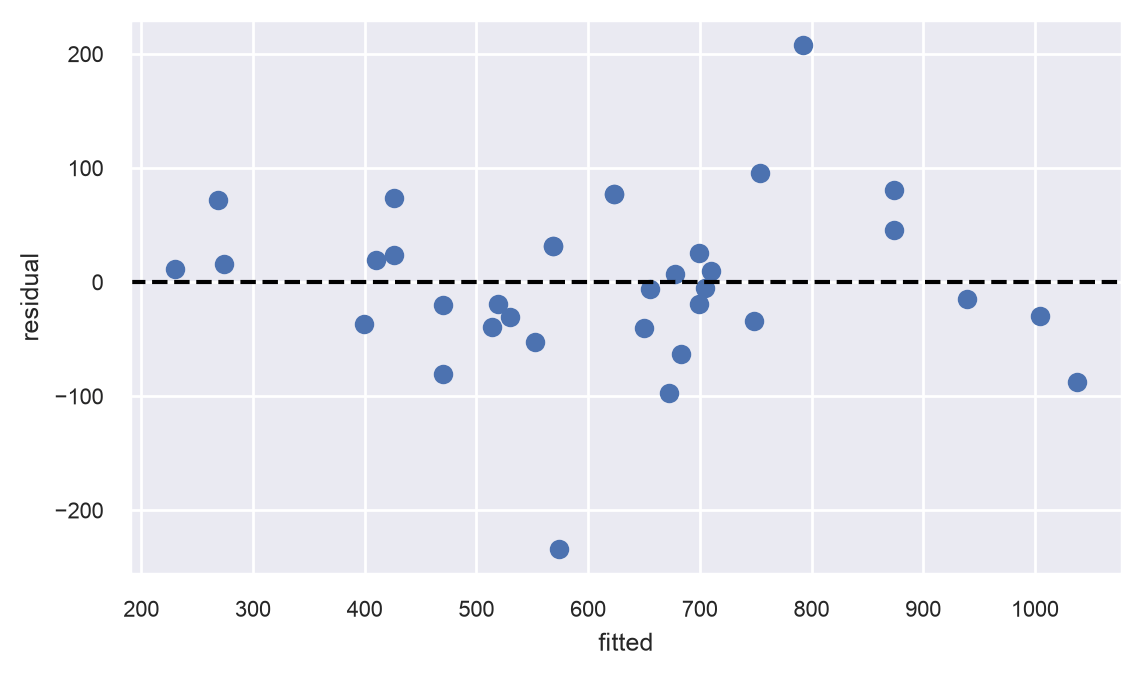

In [1247]:
# the same plot in object-oriented style (ax. methods)
slope, intercept, *_ = stats.linregress(col_x, col_y)
col_pred = col_x * slope + intercept
col_res = col_y - col_pred
fig, ax = plt.subplots()
ax.scatter(col_pred, col_res)
ax.axhline(0, color="black", linestyle="--")
ax.set_xlabel("fitted")
ax.set_ylabel("residual");

In [1248]:
spread = col_res.groupby(pd.cut(col_pred, bins=4), observed=True).std()
ratio = spread.max() / spread.min()
f'The residuals average {round(col_res.mean(), 1) + 0.0} g. Across four equal-width groups of fitted values their standard deviation ranges from {spread.min():.0f} g to {spread.max():.0f} g (a ratio of {ratio:.1f}), so the equal-variance assumption looks ' + ('reasonable.' if ratio < 1.5 else 'doubtful.')

'The residuals average 0.0 g. Across four equal-width groups of fitted values their standard deviation ranges from 38 g to 87 g (a ratio of 2.3), so the equal-variance assumption looks doubtful.'

*See also:* Drawing a residual plot (C3) · Drawing a horizontal line (C1) · Residual plots with seaborn (D5) · Residuals across binned fitted values (D5)

#### Residuals across binned fitted values

**D5.28**

`pd.cut(df['pred'], bins=4); sns.boxplot(data=df, x='pred_group', y='res')`

***(non-examinable)***

If the fitted values are cut into bins, then a box plot of the residuals for each bin shows whether the spread and the centre of the residuals stay the same across the range of the fit. It is useful as a check of the linear and equal-variance assumptions, because boxes that widen or drift away from zero signal a problem. Alternatively, plot the residuals against the fitted values directly.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

In [1249]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
df_resid = df_bream[["length1", "weight"]].copy()
df_resid["pred"] = df_resid["length1"] * slope + intercept
df_resid["res"] = df_resid["weight"] - df_resid["pred"]
df_resid.head()

,length1,weight,pred,res
0,23.2,242.0,230.211993,11.788007
1,24.0,290.0,273.851977,16.148023
2,23.9,340.0,268.396979,71.603021
3,26.3,363.0,399.316934,-36.316934
4,26.5,430.0,410.226930,19.773070


`bins=4` cuts the fitted values into four equal-width groups:

In [1250]:
df_resid["pred_group"] = pd.cut(df_resid["pred"], bins=4)
df_resid["pred_group"].value_counts().sort_index()

pred_group
(229.405, 432.047]      7
(432.047, 633.882]     11
(633.882, 835.717]     12
(835.717, 1037.552]     5
Name: count, dtype: int64

Each box should be centred near zero and have a similar height:

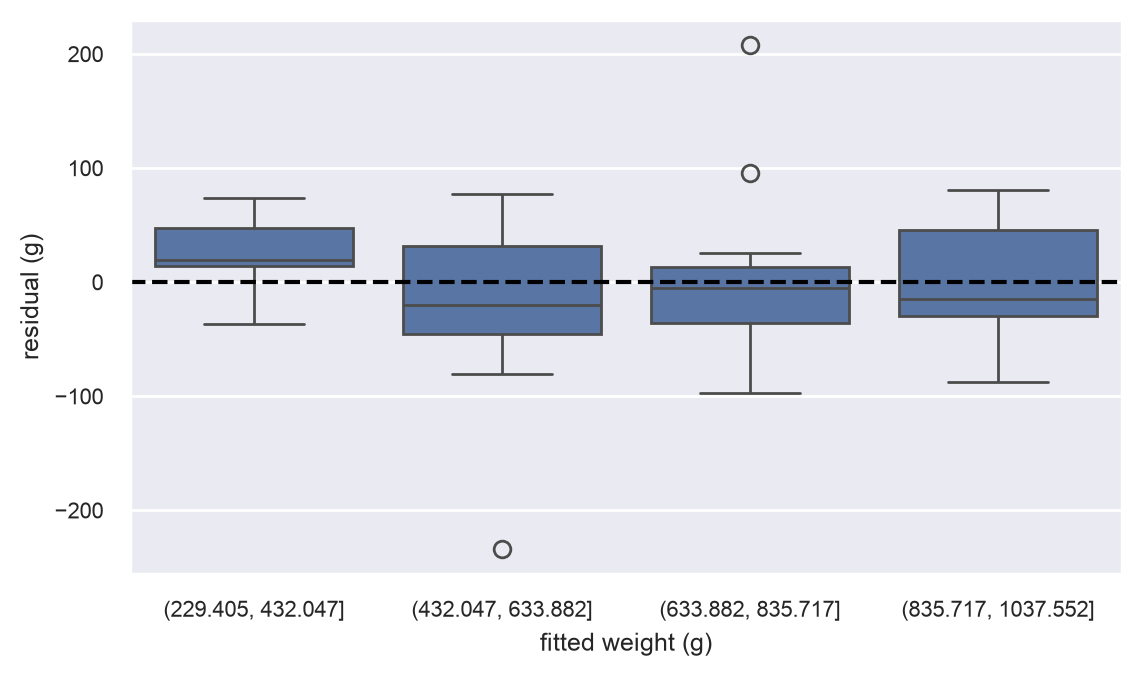

In [1251]:
sns.boxplot(data=df_resid, x="pred_group", y="res")
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("fitted weight (g)")
plt.ylabel("residual (g)");

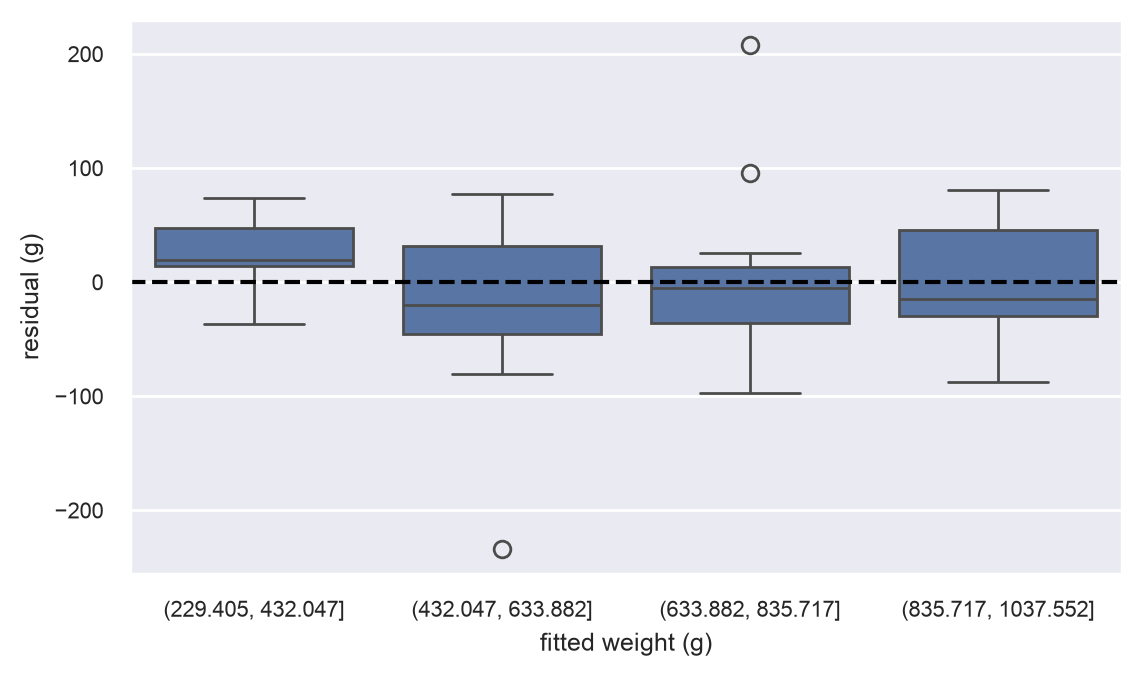

In [1252]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
sns.boxplot(data=df_resid, x="pred_group", y="res", ax=ax)
ax.axhline(0, color="black", linestyle="--")
ax.set_xlabel("fitted weight (g)")
ax.set_ylabel("residual (g)");

In [1253]:
spread = df_resid.groupby("pred_group", observed=True)["res"].std()
f'The standard deviation of the residuals ranges from {spread.min():.0f} g to {spread.max():.0f} g across the four groups, a ratio of {spread.max() / spread.min():.1f}; ' + ('the spread is similar in every group.' if spread.max() / spread.min() < 1.5 else 'the spread differs between groups, so the equal-variance assumption is doubtful.')

'The standard deviation of the residuals ranges from 38 g to 87 g across the four groups, a ratio of 2.3; the spread differs between groups, so the equal-variance assumption is doubtful.'

*See also:* Residuals versus fitted values (D5) · The LINE assumptions (D5) · Binning numbers into categories (B4)

#### Residual plots with seaborn

**D5.14**

`sns.residplot(data=df, x='col_1', y='col_2')`

The `sns.residplot()` function allows us to plot residuals against x in one call. It is useful as a quick check of the linearity assumption. Alternatively, calculate the residuals and plot them with `plt.scatter`.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

In [1254]:
# display the example data
df_bream[["length1", "weight"]].head()

,length1,weight
0,23.2,242.0
1,24.0,290.0
2,23.9,340.0
3,26.3,363.0
4,26.5,430.0


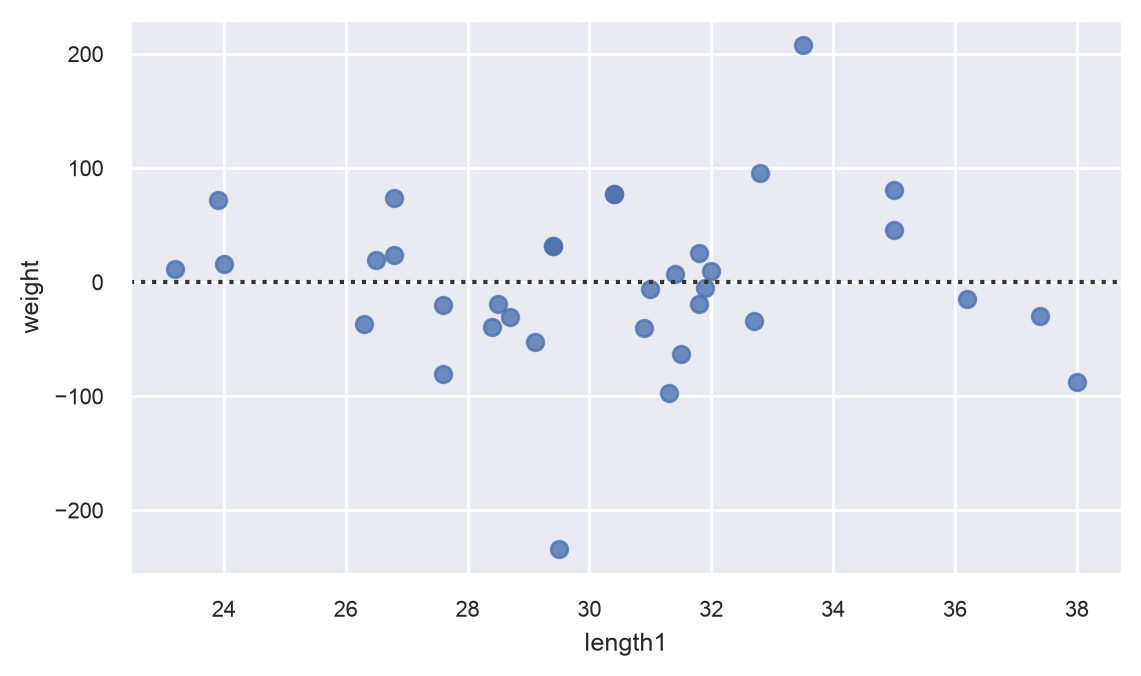

In [1255]:
sns.residplot(data=df_bream, x="length1", y="weight");

*See also:* Residuals versus fitted values (D5) · Drawing a residual plot (C3) · Checking the fit with `regplot` (D5)

#### QQ plots of residuals

**D5.15**

`stats.probplot(residuals, dist="norm", plot=plt)`

A QQ plot of the residuals allows us to check they are roughly normal, as regression assumes. It is useful for spotting skew and heavy tails. Alternatively, `stats.shapiro` gives a p-value.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

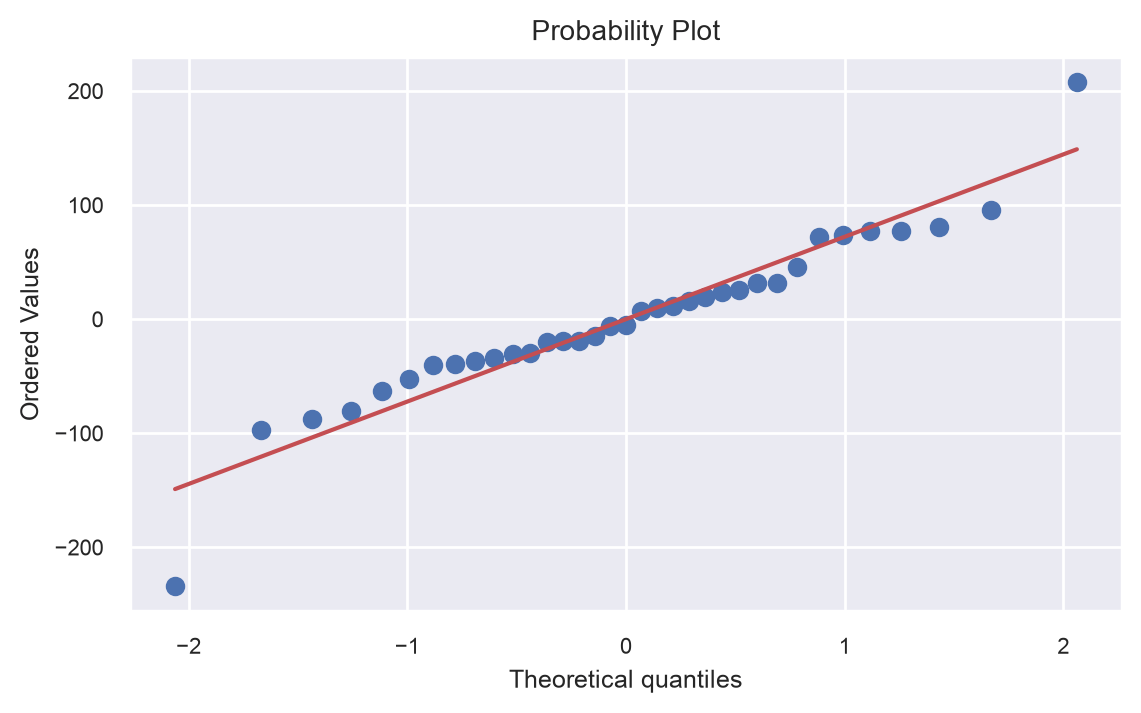

In [1256]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
col_res = col_y - (col_x * slope + intercept)
stats.probplot(col_res, dist="norm", plot=plt);

*See also:* Testing for normality (D4) · QQ plots (D4) · Testing the residuals for normality (D5)

#### Testing the residuals for normality

**D5.16**

`stats.shapiro(residuals)`

The `stats.shapiro()` function allows us to test whether the residuals are normally distributed. It is useful as a formal check alongside the QQ plot. Alternatively, rely on the QQ plot for large samples.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Note: the null hypothesis is that the residuals are normal. With a large sample the test flags trivial departures, and with a small sample it has little power, so it is read together with the QQ plot.

In [1257]:
slope, intercept, *_ = stats.linregress(col_x, col_y)
col_res = col_y - (col_x * slope + intercept)
res_sw = stats.shapiro(col_res)
print(f"W = {res_sw.statistic:.3f}, p = {res_sw.pvalue:.4g}")

W = 0.937, p = 0.04693


In [1258]:
'The Shapiro-Wilk p-value is ' + f'{res_sw.pvalue:.4g}' + (', below 0.05, so there is evidence that the residuals are not normal.' if res_sw.pvalue < 0.05 else ', not below 0.05, so there is no evidence at the 5% level against normal residuals.')

'The Shapiro-Wilk p-value is 0.04693, below 0.05, so there is evidence that the residuals are not normal.'

*See also:* Testing for normality (D4) · QQ plots of residuals (D5) · The LINE assumptions (D5)

#### The LINE assumptions

**D5.17**

`Linear, Independent, Normal, Equal variance`

The four LINE assumptions allow us to judge whether a regression is trustworthy: Linear, Independent, Normal and Equal variance residuals.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

- **L**inear: the relationship is a straight line (residuals show no curve).
- **I**ndependent: residuals are not correlated with each other.
- **N**ormal: residuals are roughly normal (QQ plot, Shapiro).
- **E**qual variance: residual spread is the same everywhere (no funnel).

A curved relationship breaks the **L** assumption, and the residuals show a U shape:

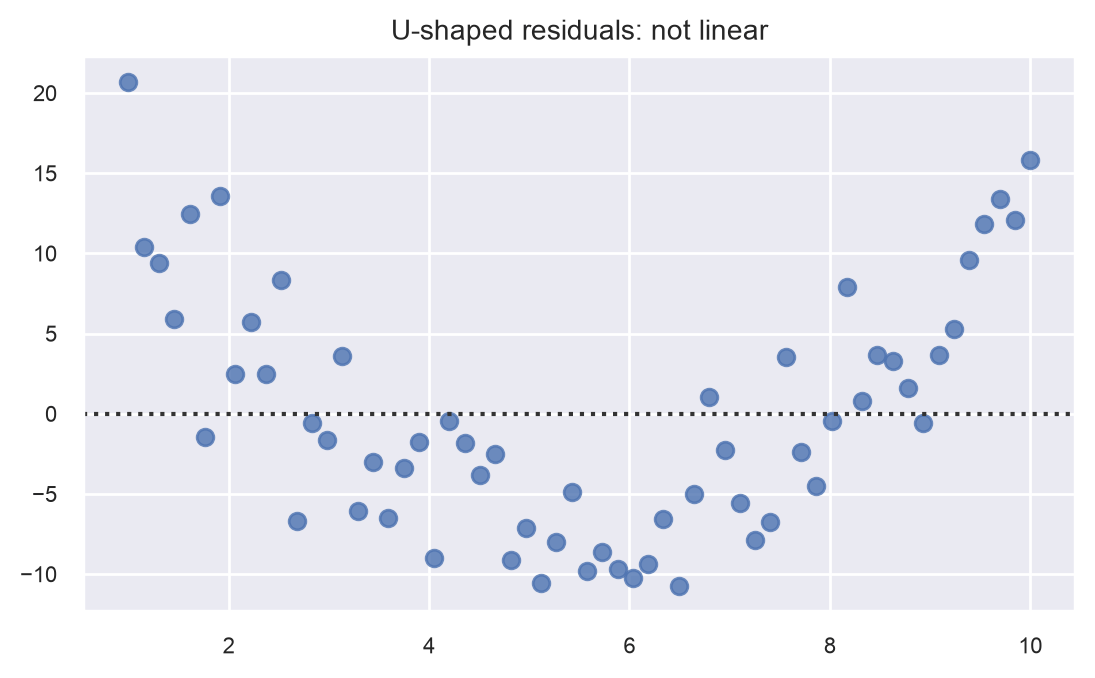

In [1259]:
np.random.seed(1)                          # fixed seed, so the output is repeatable
xs = np.linspace(1, 10, 60)
ys = xs ** 2 + np.random.normal(0, 4, 60)
sns.residplot(x=xs, y=ys)
plt.title("U-shaped residuals: not linear");

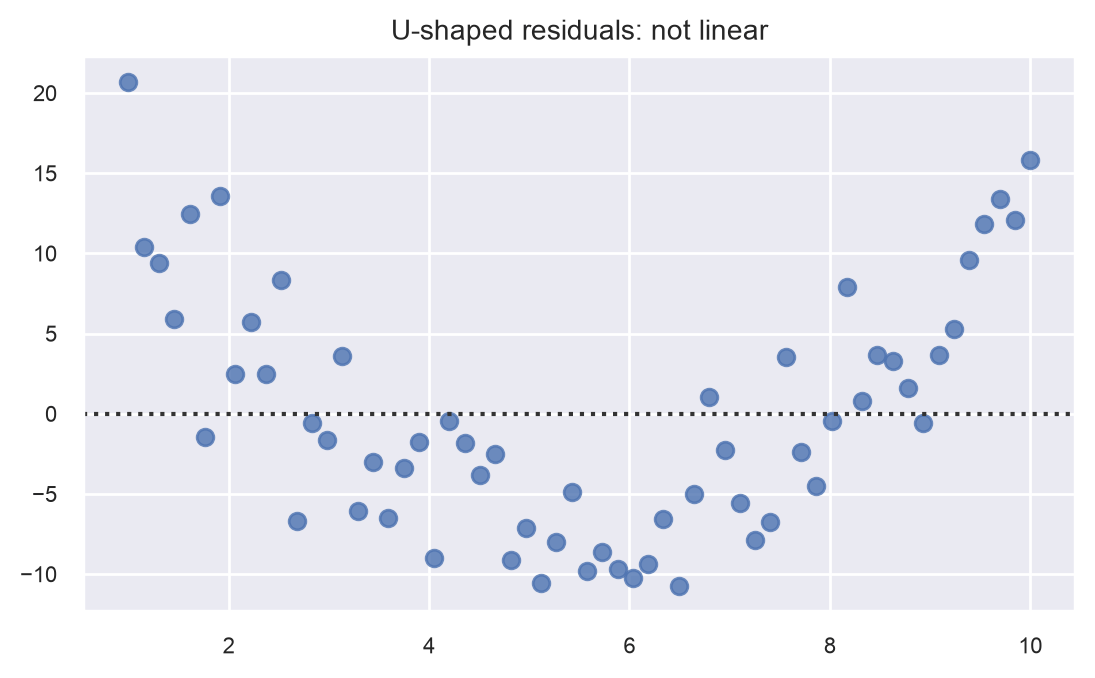

In [1260]:
# the same plot in object-oriented style (ax. methods)
np.random.seed(1)                          # fixed seed, so the output is repeatable
xs = np.linspace(1, 10, 60)
ys = xs ** 2 + np.random.normal(0, 4, 60)
fig, ax = plt.subplots()
sns.residplot(x=xs, y=ys, ax=ax)
ax.set_title("U-shaped residuals: not linear");

Note: the `statsmodels` diagnostics report these checks numerically.

*See also:* Fitting a model with a formula (D5) · Residuals versus fitted values (D5) · QQ plots of residuals (D5) · The Durbin-Watson statistic (D5)

### Transformations

#### Log-log models

**D5.18**

`df['log_y'] = np.log10(df['y'])`

If a relationship is curved (a power law), then taking logs of both variables can straighten it so a straight-line fit works. It is useful for growth and size relationships. Alternatively, fit a curve directly, though that needs more advanced tools.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: the LINE assumptions must be checked again on the log scale, for example with a residual plot of the log values. A log transformation is chosen to help them hold; it does not guarantee that they do.

In [1261]:
# display the example data
df_bream[["length1", "weight"]].head(3)     # before

,length1,weight
0,23.2,242.0
1,24.0,290.0
2,23.9,340.0


In [1262]:
df_bream["log_weight"] = np.log10(df_bream["weight"])
df_bream["log_length"] = np.log10(df_bream["length1"])
lr = stats.linregress(df_bream["log_length"], df_bream["log_weight"])
rvalue_raw = stats.linregress(col_x, col_y).rvalue
print(f"slope = {lr.slope:.3f}, R² = {lr.rvalue ** 2:.4f}")

slope = 2.841, R² = 0.8745


In [1263]:
# display example data
df_bream[["log_length", "log_weight"]].head(3)

,log_length,log_weight
0,1.365488,2.383815
1,1.380211,2.462398
2,1.378398,2.531479


In [1264]:
print(f"On the log scale the line explains {lr.rvalue ** 2:.1%} of the variation in log weight; on the original scale it explained {rvalue_raw ** 2:.1%} of the variation in weight. "
      "The two R² values measure different quantities, so they cannot decide between the fits on their own: the residual plots on each scale do that.")

On the log scale the line explains 87.4% of the variation in log weight; on the original scale it explained 87.8% of the variation in weight. The two R² values measure different quantities, so they cannot decide between the fits on their own: the residual plots on each scale do that.


*See also:* Adding a column with a NumPy function (B4) · Using a log scale (C1) · Back-transforming predictions (D5) · The LINE assumptions (D5)

#### Back-transforming predictions

**D5.19**

`10 ** pred`

If we fitted a model on log values, then raising 10 to the predicted value turns it back into original units. It is useful after any log transformation. Alternatively, `np.exp` undoes natural logs.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Note: a prediction back-transformed from the log scale estimates the median weight, not the mean, and is slightly smaller than the mean.

In [1265]:
lr = stats.linregress(np.log10(col_x), np.log10(col_y))
pred_log = np.log10(30) * lr.slope + lr.intercept
print(f"predicted log10(weight) = {pred_log:.3f}")

predicted log10(weight) = 2.761


In [1266]:
print(f"back-transformed weight    = {10 ** pred_log:.0f} g")

back-transformed weight    = 576 g


*See also:* Applying maths functions to an array (A4) · Log-log models (D5) · Calculating powers and square roots (A1) · Predicting a single value (D5)

### statsmodels (optional)

#### Fitting a model with a formula

**D5.20**

`model = smf.ols('y ~ x', data=df).fit()`

***(non-examinable)***

The `smf.ols("y ~ x", data=df).fit()` function allows us to fit a regression using a formula. It is useful for fuller output (confidence intervals, tests) and for several predictors. Alternatively, `stats.linregress` fits a line with one predictor and no formula.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: the same as for `linregress` (the LINE assumptions). The standard errors, p-values and confidence intervals in the output rely on them.
Needs `%pip install statsmodels` if missing.

In [1267]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [1268]:
model = smf.ols("weight ~ length1", data=df_bream).fit()
model.params

Intercept   -1035.347565
length1        54.549981
dtype: float64

*See also:* Fitting a line (D5) · The full model summary (D5) · The LINE assumptions (D5) · Multiple regression (D5)

#### The full model summary

**D5.21**

`model.summary()`

***(non-examinable)***

The `model.summary()` method allows us to see coefficients, standard errors, p-values, R² and diagnostics in one table. It is useful for a complete report of a fit. Alternatively, pick individual numbers from `model.params` and friends.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: the p-values and confidence intervals in this table are valid only if the residuals are independent, approximately normal and of equal variance. The Omnibus and Jarque-Bera lines test normality, and the Durbin-Watson line tests independence.

In [1269]:
import statsmodels.formula.api as smf

In [1270]:
model = smf.ols("weight ~ length1", data=df_bream).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 weight   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.874
Method:                 Least Squares   F-statistic:                     237.6
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           1.22e-16
Time:                        07:23:09   Log-Likelihood:                -199.35
No. Observations:                  35   AIC:                             402.7
Df Residuals:                      33   BIC:                             405.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1035.3476    107.973     -9.589      0.000   -1255.020    -815.676
length1       54.5500      3.539     15.415      0.000      47.350      61.750
==============================================================================
Omnibus:                        7.314   Durbin-Watson:                   1.478
Prob(Omnibus):                  0.026   Jarque-Bera (JB):               10.857
Skew:                          -0.252   Prob(JB):                      0.00439
Kurtosis:                       5.682   Cond. No.                         263.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

*See also:* Fitting a model with a formula (D5) · Extracting single results from a model (D5) · The LINE assumptions (D5)

#### Extracting single results from a model

**D5.22**

`model.params, model.rsquared, model.pvalues`

***(non-examinable)***

Attributes such as `.params`, `.rsquared` and `.pvalues` allow us to extract single numbers from a fitted model. They are useful for quoting results in text. Alternatively, `model.summary().tables` gives the tables.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

In [1271]:
import statsmodels.formula.api as smf

In [1272]:
model = smf.ols("weight ~ length1", data=df_bream).fit()
print(f"slope     = {model.params['length1']:.2f}")

slope     = 54.55


In [1273]:
print(f"intercept = {model.params['Intercept']:.2f}")

intercept = -1035.35


In [1274]:
print(f"R²        = {model.rsquared:.4f}")

R²        = 0.8781


In [1275]:
print(f"p (slope) = {model.pvalues['length1']:.3g}")

p (slope) = 1.22e-16


*See also:* The full model summary (D5) · Reporting a regression (D5) · Fitted values and residuals (D5)

#### Fitted values and residuals

**D5.23**

`model.fittedvalues, model.resid, sm.qqplot(model.resid, line='r')`

***(non-examinable)***

The `.fittedvalues` and `.resid` attributes allow us to get predictions and residuals, and `sm.qqplot` draws their QQ plot. They are useful for assumption checks on a fitted model. Alternatively, calculate them from the predictions as shown earlier.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

In [1276]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [1277]:
model = smf.ols("weight ~ length1", data=df_bream).fit()
model.resid.head(3).round(1).tolist()

[11.8, 16.1, 71.6]

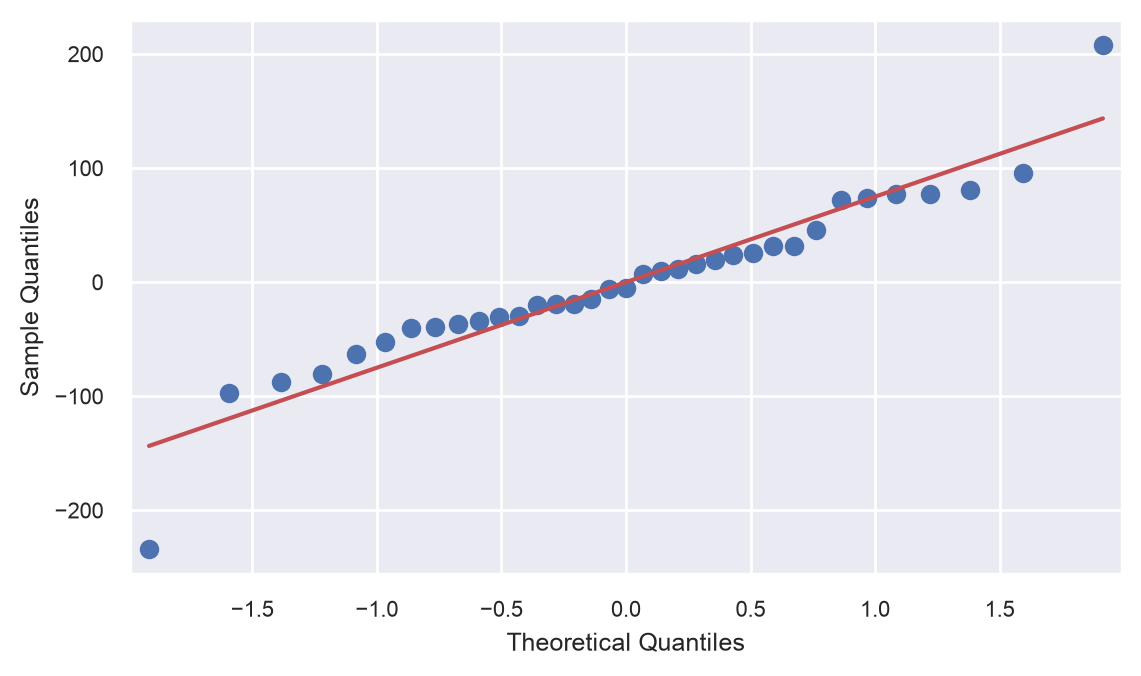

In [1278]:
sm.qqplot(model.resid, line="r");

*See also:* Residuals (D5) · QQ plots of residuals (D5) · The LINE assumptions (D5)

#### The Durbin-Watson statistic

**D5.24**

`durbin_watson(res)`

***(non-examinable)***

The `durbin_watson()` function allows us to test whether residuals are independent of one another. It is useful for ordered data (time series). Values near 2 suggest independence. Alternatively, calculate it from `np.diff` of the residuals.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumption: independence of the residuals (the I in LINE). Observations ordered in time, or collected in groups, often break it. The bream rows are not in time order, so the value here only shows the calculation: the statistic means something only when the rows have a natural order.

In [1279]:
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson

In [1280]:
model = smf.ols("weight ~ length1", data=df_bream).fit()
res = model.resid.values
print(f"statsmodels: {round(durbin_watson(res), 3)}")

statsmodels: 1.478


In [1281]:
print(f"by hand    : {round(np.sum(np.diff(res) ** 2) / np.sum(res ** 2), 3)}")

by hand    : 1.478


*See also:* Taking differences and sums of an array (A4) · The LINE assumptions (D5) · Confidence intervals and predictions (D5) · Residuals (D5)

#### Confidence intervals and predictions

**D5.25**

`model.conf_int(), model.predict(df_new)`

***(non-examinable)***

The `model.conf_int()` and `model.predict()` methods allow us to get intervals for the coefficients and predictions for new data. They are useful for reporting uncertainty. Alternatively, build intervals from `stderr` and `stats.t.ppf`.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: the intervals rely on the LINE assumptions. A prediction interval also needs normal residuals with constant variance, and is unreliable outside the range of the data.

In [1282]:
import statsmodels.formula.api as smf

In [1283]:
model = smf.ols("weight ~ length1", data=df_bream).fit()
model.conf_int()

,0,1
Intercept,-1255.019582,-815.675548
length1,47.350452,61.749510


In [1284]:
model.predict(pd.DataFrame({"length1": [30]}))

0    601.151863
dtype: float64

*See also:* Critical t values (D4) · Confidence intervals (D4) · Predicting a single value (D5) · Multiple regression (D5) · The LINE assumptions (D5)

#### Multiple regression

**D5.26**

`smf.ols('y ~ x1 + x2', data=df).fit()`

***(non-examinable)***

Adding more terms to the formula (`y ~ x1 + x2`) allows us to model several predictors at once. It is useful when one variable alone does not explain the outcome. Alternatively, fit separate simple regressions and compare.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: the LINE assumptions hold for the model as a whole, and the predictors are not strongly correlated with each other. Strong correlation (collinearity) makes the individual coefficients unstable; a correlation heatmap checks this.

In [1285]:
import statsmodels.formula.api as smf

In [1286]:
m2 = smf.ols("weight ~ length1 + height", data=df_bream).fit()
m2.params.round(2)

Intercept   -1006.27
length1        15.35
height         76.34
dtype: float64

*See also:* Fitting a model with a formula (D5) · The full model summary (D5) · A separate line per group (D5) · Drawing a correlation heatmap (C3)

#### A separate line per group

**D5.27**

`sns.lmplot(data=df, x='col_1', y='col_2', hue='group')`

***(non-examinable)***

The `sns.lmplot(hue=...)` function allows us to fit a separate regression line for each group. It is useful for seeing whether groups follow different relationships. Alternatively, fit `smf.ols` with an interaction term.

**Context.** The data are the length (cm) and weight (g) of Bream, a species of fish, from the course fish data. The aim is to describe and predict weight from length.

Assumptions: a straight line is appropriate within each group, and the spread of the residuals is similar in every group.

In [1287]:
# display the example data
df_fish[["species", "length1", "weight"]].head()

,species,length1,weight
0,Bream,23.2,242.0
1,Bream,24.0,290.0
2,Bream,23.9,340.0
3,Bream,26.3,363.0
4,Bream,26.5,430.0


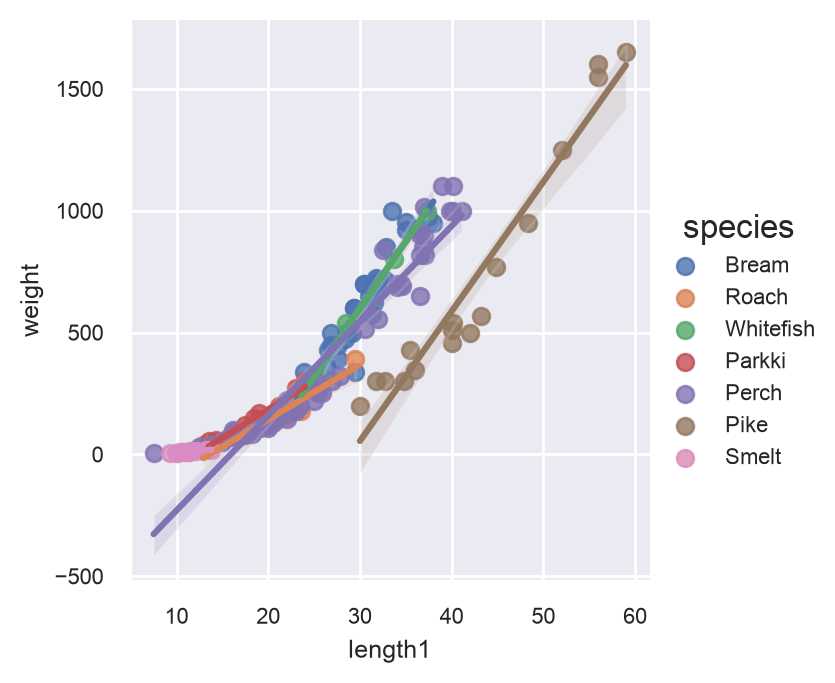

In [1288]:
sns.lmplot(data=df_fish, x="length1", y="weight", hue="species", height=3.5);

*See also:* Fitting a model with a formula (D5) · Checking the fit with `regplot` (D5) · Colouring points by group (C3) · The LINE assumptions (D5)